# TD1 — De la donnée au premier modèle de Machine Learning

Pour commencer 
```bash 
python3 -m venv "new_env"
source new_env\bin\activate
pip install numpy pandas scikit-learn matplotlib
```

## 1. Charger le jeu de données et exploration des données 
1. Utiliser la commande load_iris de sklearn.datasets pour charger le jeu de données iris
2. Créer une `DataFrame` contenant les variables explicatives (X) et la variables décrite (y)

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [24]:
from sklearn.datasets import load_iris

In [ ]:
iris = load_iris()
print(f"Feature names: {iris.feature_names}")
print(f"Target names: {iris.target_names}")


Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']


In [9]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target

In [10]:
df.head(n=10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0


## Quel est le type de problème (régression, classification, similarité, clustering ...) ? 
- classification mutli-classes (3 classes : setosa,versicolor, virginica)


## 3. Identifier X et y

En apprentissage supervisé :
- **X** = variables explicatives utilisées pour prédire ;
- **y** = variable cible à prédire.

### Questions
1. Quelles colonnes appartiennent à X ?
2. Quelle colonne correspond à y ?
3. Classification ou régression ?
4. Combien de classes ?
5. Les classes sont-elles équilibrées ?

Construisez `X` et `y`, puis vérifiez leurs dimensions.

In [12]:
X = iris.data
y = iris.target

print(type(X))
print(type(y))
print(f"X shape: {X.shape} ")
print(f"y shape: {y.shape}")
print(f"Class : {np.unique(y)}")

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
X shape: (150, 4) 
y shape: (150,)
Class : [0 1 2]


## 4. Créer un jeu d'entrainement et un jeu de test 
Utiliser `train_test_split` avec les paramètre suivant:
- `test_size`
- `random_state`
- `shuffle` 
- `stratify` 

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20, 
    random_state=42, 
    stratify=y, 
    shuffle=True
)

In [57]:
print(f"Train set shape {X_train.shape}, {y_train.shape}")
print(f"Test set shape {X_test.shape}, {y_test.shape}")

Train set shape (120, 4), (120,)
Test set shape (30, 4), (30,)


## 5 : Premier modèle : régression logistique
Une régression logistique est un modèle spécialisé dans la classification d'instance à partir d'une relation linéaire 

1.  Importer `LogisticRegression` à partir de `sklearn.linear_model`
2. Créer le modèle
3. Entrainer le modèle avec la fonction fit()

In [58]:
from sklearn.linear_model import LogisticRegression

In [59]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## 6. Faire des prédictions

1. Utiliser `predict()` sur X_test ou une instance de X_test
2. Comparer `y_test` et `y_pred` sur une dizaine d'instance

In [60]:
y_pred = model.predict(X_test)
comp = pd.DataFrame({"vraie_classe": y_test, "prediction": y_pred})
comp.head(10)

,vraie_classe,prediction
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


## 7. Evaluer la performance du modèle

1. Utiliser une matrice de confusion
   1. Calculer la matrice de confusion avec `sklearn.metrics.confusion_matrice`
   2. Afficher la matrice avec `ConfusionMatrixDisplay`
   3. Identifiez les éventuelles erreurs. 
   
2. Utiliser l'accuracy pour évaluer la performance du modèle (`sklearn.metrics.accuracy_score`): 

$$Accuracy = \frac{\text{prédictions correctes}}{\text{prédictions totales}}$$




In [61]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

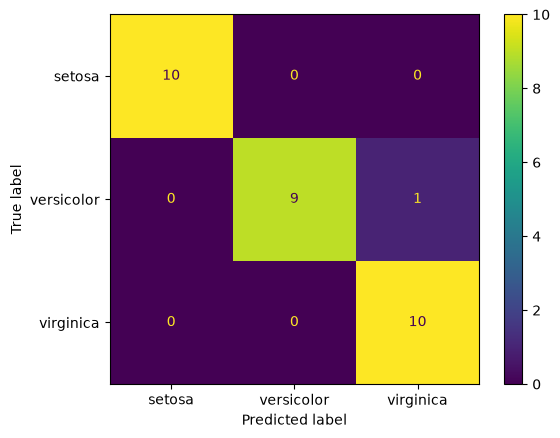

In [62]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot()
plt.show()

In [63]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}")

Accuracy: 0.967


## 8. Comparer avec un deuxième modèle : La fôret d'arbre aléatoire

Créer un second modèle avec `sklearn.ensemble.RandomForestClassifier` et les paramètre suivants : 
* n_estimators = 100
* max_depth = 10

In [64]:
from sklearn.ensemble import RandomForestClassifier

In [65]:
model2 = RandomForestClassifier(n_estimators=100)
model2.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [66]:
y_pred = model2.predict(X_test)

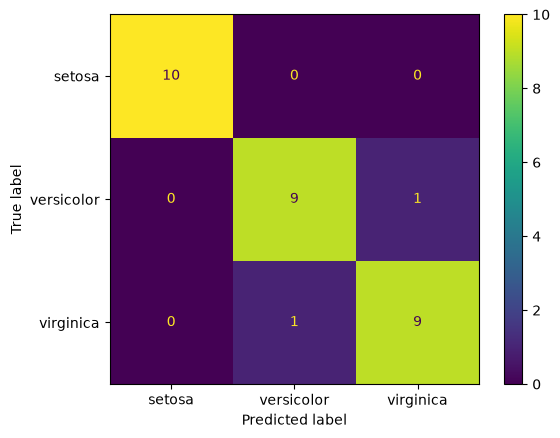

In [67]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot()
plt.show()

In [68]:
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}")

Accuracy: 0.933


## Pour aller plus loin : 

1. Test d'autre modèles (XGBoost, LightGBM...)
2. Adapter les paramètres des modèles (cf doc)
3. Tester d'autre dataset